In [1]:
import os
os.chdir("/Users/natalynpong/fyp/ivsn-pytorch/codes")

import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from utils import model_performance

with open("../results/NaturalDesign/IVSN_res_myrun.pkl", "rb") as f:
    IVSN_res = pickle.load(f)
IVSN_accu = model_performance(IVSN_res, len(IVSN_res))
print(len(IVSN_res), len(IVSN_accu), IVSN_accu[:10])

240 100 [0, np.float64(0.1125), np.float64(0.24583333333333332), np.float64(0.35833333333333334), np.float64(0.44583333333333336), np.float64(0.5041666666666667), np.float64(0.5791666666666667), np.float64(0.6375), np.float64(0.6916666666666667), np.float64(0.7166666666666667)]


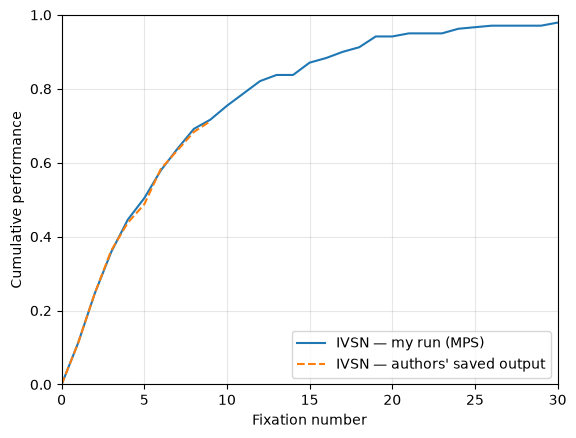

In [13]:
authors = [0, 0.1125, 0.24583333333333332, 0.3625, 0.4375, 0.4875,
           0.5833333333333334, 0.6333333333333333, 0.6833333333333333, 0.7125]

import matplotlib.pyplot as plt
plt.plot(range(len(IVSN_accu)), IVSN_accu, label="IVSN — my run (MPS)")
plt.plot(range(len(authors)), authors, "--", label="IVSN — authors' saved output")
plt.xlabel("Fixation number"); plt.ylabel("Cumulative performance")
plt.xlim(0, 30); plt.ylim(0, 1); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("../results/NaturalDesign/fig3b_model_myrun.png", dpi=200, bbox_inches="tight")
plt.show()

In [2]:
from scipy.io import loadmat
m = loadmat("dataset/naturaldesign/psy/naturaldesign.mat",
            squeeze_me=True, struct_as_record=False)
for k, v in m.items():
    if k.startswith("__"):
        continue
    print(k, type(v).__name__, getattr(v, "shape", ""))

MyData ndarray (480,)


In [3]:
from scipy.io import loadmat
m = loadmat("dataset/naturaldesign/psy/naturaldesign.mat", squeeze_me=True)

# MyData is the trial-to-image index, not fixation data: uint8 (480,).
# Entries 0-239 are the first presentations of images 1..240;
# entries 240-479 are the repeat presentations of the same images.
trial_image_id = m["MyData"]
print("trial_image_id:", trial_image_id.dtype, trial_image_id.shape)
print("first 10:", trial_image_id[:10])
print("last 10 :", trial_image_id[-10:])

trial_image_id: uint8 (480,)
first 10: [ 1  2  3  4  5  6  7  8  9 10]
last 10 : [231 232 233 234 235 236 237 238 239 240]


In [4]:
import glob
import numpy as np
from scipy.io import loadmat

files = sorted(glob.glob("dataset/naturaldesign/psy/ProcessScanpath_naturaldesign/*.mat"))
print("subjects:", len(files))
print([f.split("/")[-1] for f in files])

s  = loadmat(files[0], squeeze_me=True, struct_as_record=False)
fd = s["FixData"]

for f in fd._fieldnames:
    v = getattr(fd, f)
    print(f"  {f:16s} {type(v).__name__:12s} {getattr(v, 'shape', '')}")

tf = np.asarray(fd.TargetFound)
px = np.asarray(fd.Fix_posx)
print("\nTargetFound     :", tf.shape, tf[:20])
print("Fix_posx trial 0:", np.atleast_1d(px[0]))
print("fixation counts :", [len(np.atleast_1d(px[i])) for i in range(8)])
print("clickwrong      :", np.asarray(s["subjclickwrong"])[:20])

subjects: 31
['subj01-mm.mat', 'subj02-az.mat', 'subj02-az_oracle.mat', 'subj03-el.mat', 'subj03-el_oracle.mat', 'subj04-ni.mat', 'subj04-ni_oracle.mat', 'subj05-mi.mat', 'subj05-mi_oracle.mat', 'subj06-st.mat', 'subj06-st_oracle.mat', 'subj07-pl.mat', 'subj07-pl_oracle.mat', 'subj09-an.mat', 'subj09-an_oracle.mat', 'subj10-ni.mat', 'subj10-ni_oracle.mat', 'subj11-ta.mat', 'subj11-ta_oracle.mat', 'subj12-mi.mat', 'subj12-mi_oracle.mat', 'subj13-zw.mat', 'subj13-zw_oracle.mat', 'subj14-ji.mat', 'subj14-ji_oracle.mat', 'subj15-ra.mat', 'subj15-ra_oracle.mat', 'subj16-kr.mat', 'subj16-kr_oracle.mat', 'subj17-ke.mat', 'subj17-ke_oracle.mat']
  Fix_posx         ndarray      (480,)
  Fix_posy         ndarray      (480,)
  TargetFound      ndarray      (480, 65)
  Fix_time         ndarray      (480,)
  Fix_starttime    ndarray      (480,)
  Mouseclicktime   ndarray      (480,)

TargetFound     : (480, 65) [[0 1 0 ... 0 0 0]
 [0 0 1 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 1 0